# Generador de Gráficos 1.1 a 1.3 (Estandarizado Villa Gaucho)

Este cuaderno implementa el generador estandarizado para las preguntas 1.1, 1.2 y 1.3 con las correcciones y especificaciones solicitadas:
- **Gráficos de Barras VERTICALES (Cuantitativas discretas)**:
  - Para 1.1.1, 1.2.1 y 1.3.1 (cantidad de personas).
  - **Regla del 2%**: Si el porcentaje es menor a 2%, la frecuencia absoluta aparece **afuera de la barra** arriba (`"X (Y,Y%)"`). Si es >= 2%, la frecuencia aparece **adentro de la barra** en blanco y negrita (tamaño 14).
  - Color institucional: **`#1b7882`**.
- **Gráficos de Torta (Cualitativas - Género)**:
  - Para 1.1.2, 1.2.2 y 1.3.2.
  - **Filtro de categorías conocidas**: Se basan en un dataset filtrado que excluye la categoría *'Se desconoce'*, considerando exclusivamente: **Mujer**, **Varón** y **Mujer - Varón**.
  - **Líneas blancas divisorias** entre las partes de la torta (`edgecolor='white', linewidth=1.5`).
  - **Porcentajes adentro** de cada cuña (en negrita, tamaño 14, formato `X,X%`).
  - **Línea conectora con doblez en 2 tramos (diagonal + horizontal)**: arranca de un punto indicador en la cuña y finaliza justo donde comienza el texto, **sin subrayar**.
  - **Nombre de la categoría arriba** y **frecuencia absoluta con unidad abajo** (`X hogares`, `1 hogar`).
  - Orden estricto de mayor a menor porcentaje con la paleta de Villa Gaucho: 1. Azul (`#4285F4`), 2. Naranja (`#FB8C00`), 3. Verde (`#34A853`), 4. Amarillo (`#FBBC05`), 5. Violeta (`#8E24AA`), 6. Beige (`#D7CCC8`).
  - Distribución balanceada verticalmente en el recuadro para evitar superposiciones.


In [1]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración global de tamaño de letra 14 para todo el cuaderno
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.titlesize'] = 14

# Paleta para tortas (de mayor a menor porcentaje)
PALETA_TORTA = [
    '#4285F4',  # 1. Azul
    '#FB8C00',  # 2. Naranja
    '#34A853',  # 3. Verde
    '#FBBC05',  # 4. Amarillo
    '#8E24AA',  # 5. Violeta
    '#D7CCC8'   # 6. Beige
]

# Color estándar para barras de un solo color
COLOR_BARRAS_UNICO = '#1b7882'


In [2]:
# ==============================================================================
# 2. FUNCIONES DE GRAFICACIÓN ESTANDARIZADAS
# ==============================================================================
def graficar_barras_verticales(etiquetas, valores, titulo="", xlabel="Cantidad de personas", ylabel="Cantidad de respuestas", figsize=(9, 6)):
    """
    Genera un gráfico de barras VERTICAL estandarizado:
    - Si porcentaje < 2%, frecuencia y porcentaje van afuera de la barra (arriba).
    - Si porcentaje >= 2%, frecuencia adentro de la barra (blanco, negrita) y porcentaje arriba.
    - Color #1b7882.
    """
    valores = np.array(valores, dtype=float)
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)
    x_pos = np.arange(n)

    fig, ax = plt.subplots(figsize=figsize)

    barras = ax.bar(
        x_pos,
        valores,
        color=COLOR_BARRAS_UNICO,
        width=0.62,
        edgecolor='none'
    )

    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(lbl) for lbl in etiquetas], fontsize=14)

    max_h = max(valores) if len(valores) > 0 else 1

    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        h = barra.get_height()
        x = barra.get_x() + barra.get_width() / 2.0

        # REGLA DEL 2%:
        if porcentaje < 2.0:
            # Afuera de la barra (arriba)
            ax.text(
                x, h + (max_h * 0.02),
                f"{int(cantidad)}\n({porcentaje:.1f}%)".replace('.', ','),
                ha='center', va='bottom',
                color='#202124', fontsize=14, fontweight='medium'
            )
        else:
            # Frecuencia adentro y porcentaje arriba
            ax.text(
                x, h / 2.0, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
            ax.text(
                x, h + (max_h * 0.02),
                f"{porcentaje:.1f}%".replace('.', ','),
                ha='center', va='bottom',
                color='#202124', fontsize=14
            )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=18, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_ylim(0, max_h * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


def graficar_torta(categorias, valores, titulo="", unidad="personas", es_binario=False, orden_positivo_primero=True, figsize=(10, 6), max_categorias_torta=3, conmutar_si_muchas_categorias=True, **kwargs):
    """
    Genera un gráfico de torta con el formato del Informe de Villa Gaucho:
    - Paleta ordenada de mayor a menor: Azul (#4285F4), Naranja (#FB8C00), Verde (#34A853), Amarillo (#FBBC05), Violeta (#8E24AA), Beige (#D7CCC8).
    - Si es binario (Sí/No): Positivo = Azul, Negativo = Naranja.
    - Porcentajes ADENTRO de la torta (en negrita, tamaño 14, formato X,X%).
    - Frecuencias absolutas AFUERA de la torta (debajo de la línea conectora con su unidad singular/plural).
    - Nombre de la categoría AFUERA de la torta (arriba de la línea conectora).
    - Líneas blancas divisorias entre porciones de la torta (edgecolor='white', linewidth=1.5).
    - Línea conectora en 2 tramos con codo (diagonal + horizontal) que arranca de un punto indicador en la cuña
      y finaliza exactamente donde comienza el texto de la categoría, sin subrayar.
    - Distribución vertical balanceada para evitar superposiciones entre categorías cercanas.
    - Si la variable posee más de 5 categorías y conmutar_si_muchas_categorias=True, conmuta automáticamente
      a un gráfico de barras horizontales con la paleta de torta.
    """
    df_temp = pd.DataFrame({'categoria': [str(c) for c in categorias], 'fi': list(valores)})

    # Conmutación automática si hay más de 5 categorías
    if conmutar_si_muchas_categorias and len(df_temp) > max_categorias_torta and not es_binario and 'graficar_barras_horizontales' in globals():
        print(f"[INFO] La variable tiene {len(df_temp)} categorías (> {max_categorias_torta}). Se grafica con barras horizontales usando la paleta de torta.")
        graficar_barras_horizontales(
            etiquetas=df_temp['categoria'],
            valores=df_temp['fi'],
            titulo=titulo,
            usar_colores_torta=True,
            ordenar_mayor_a_menor=True,
            figsize=(13, max(6, len(df_temp) * 0.8))
        )
        return

    # Asignación de colores y orden
    if es_binario:
        def es_pos(val):
            val_clean = str(val).strip().lower()
            return val_clean in ['si', 'sí', 'positivo', 'true', 'afirma', 'posee', 'tiene', 'concurre']

        df_temp['es_pos'] = df_temp['categoria'].apply(es_pos)
        if orden_positivo_primero:
            df_temp = df_temp.sort_values(by='es_pos', ascending=False).reset_index(drop=True)
        colores = [COLOR_POSITIVO if p else COLOR_NEGATIVO for p in df_temp['es_pos']]
    else:
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(df_temp))]

    cats = df_temp['categoria'].tolist()
    vals = df_temp['fi'].values

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(aspect="equal"))

    # Torta con líneas divisorias blancas y porcentajes adentro
    wedges, texts, autotexts = ax.pie(
        vals,
        autopct=lambda p: f"{p:.1f}%".replace('.', ','),
        pctdistance=0.72,
        colors=colores,
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=1, edgecolor='white', linewidth=1.5)
    )

    # Estilo porcentajes interiores (tamaño 14 y negrita)
    for at in autotexts:
        at.set_color('#1a1a1a')
        at.set_fontsize(14)
        at.set_fontweight('bold')

    # Calcular posiciones angulares y lados
    elementos = []
    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
        x = np.cos(np.deg2rad(ang))
        y = np.sin(np.deg2rad(ang))
        lado = -1 if x < 0 else 1

        elementos.append({
            'i': i,
            'x': x,
            'y': y,
            'lado': lado,
            'y_afuera': 1.15 * y
        })

    # Separación vertical balanceada para evitar solapamientos
    min_sep = 0.29
    y_min, y_max = -1.22, 1.24
    for lado_actual in (-1, 1):
        grupo = [e for e in elementos if e['lado'] == lado_actual]
        if len(grupo) <= 1:
            continue
        grupo.sort(key=lambda e: e['y_afuera'])
        for k in range(1, len(grupo)):
            if grupo[k]['y_afuera'] - grupo[k - 1]['y_afuera'] < min_sep:
                grupo[k]['y_afuera'] = grupo[k - 1]['y_afuera'] + min_sep
        if grupo[-1]['y_afuera'] > y_max:
            grupo[-1]['y_afuera'] = y_max
            for k in range(len(grupo) - 2, -1, -1):
                if grupo[k + 1]['y_afuera'] - grupo[k]['y_afuera'] < min_sep:
                    grupo[k]['y_afuera'] = grupo[k + 1]['y_afuera'] - min_sep
        if grupo[0]['y_afuera'] < y_min:
            ys = np.linspace(y_min, y_max, len(grupo))
            for k, e in enumerate(grupo):
                e['y_afuera'] = ys[k]

    # Líneas guía en 2 tramos (diagonal -> horizontal) que arrancan justo en el texto sin subrayar
    for e in elementos:
        i = e['i']
        x = e['x']
        y = e['y']
        lado = e['lado']
        y_afuera = e['y_afuera']

        # Punto sobre la cuña
        x_punto, y_punto = 0.85 * x, 0.85 * y
        x_afuera = 1.35 * lado

        # Codo donde la línea pasa de diagonal a horizontal (fuera del círculo)
        r_ext = 1.08 if abs(y_afuera - 1.15 * y) > 1e-6 else 1.15
        x_min_ext = np.sqrt(max(0.0, r_ext**2 - y_afuera**2))
        x_codo = lado * max(abs(1.15 * x), x_min_ext)
        y_codo = y_afuera

        # Fin de la recta horizontal dejando margen justo donde inicia el texto (sin subrayar)
        x_fin = x_afuera - 0.03 * lado

        # Punto gris indicador sobre la cuña
        ax.plot(x_punto, y_punto, marker='o', markersize=4, color='#8c8c8c', zorder=4)

        # Línea guía en 2 tramos: diagonal (punto -> codo) + horizontal (codo -> inicio del texto)
        ax.plot(
            [x_punto, x_codo, x_fin],
            [y_punto, y_codo, y_codo],
            color='#8c8c8c',
            lw=1.2,
            solid_joinstyle='round',
            zorder=2
        )

        # Formato de cantidad y unidad singular / plural
        cant = int(vals[i])
        if not unidad:
            texto_unidad = str(cant)
        elif cant == 1:
            if unidad.endswith('es'):
                palabra_unidad = unidad[:-2]
            elif unidad.endswith('s'):
                palabra_unidad = unidad[:-1]
            else:
                palabra_unidad = unidad
            texto_unidad = f"{cant} {palabra_unidad}"
        else:
            texto_unidad = f"{cant} {unidad}"

        alineacion_h = "right" if lado == -1 else "left"

        # 1. Nombre de la categoría ARRIBA de la línea
        ax.text(
            x_afuera,
            y_afuera + 0.015,
            cats[i],
            horizontalalignment=alineacion_h,
            verticalalignment="bottom",
            fontsize=14,
            color="#202124",
            fontweight='medium'
        )

        # 2. Frecuencia absoluta y unidad ABAJO de la línea
        ax.text(
            x_afuera,
            y_afuera - 0.035,
            texto_unidad,
            horizontalalignment=alineacion_h,
            verticalalignment="top",
            fontsize=14,
            color="#70757a"
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=20, fontweight='bold', color='#202124')

    ax.set_xlim(-1.95, 1.95)
    ax.set_ylim(-1.35, 1.35)
    plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
    plt.show()


## 3. Carga y Procesamiento de Datos


In [3]:
# Cargar el archivo CSV con los datos del proyecto
df = pd.read_csv('datos.csv')

# Subconjuntos de datos completos para las preguntas 1.1, 1.2 y 1.3
df_1_1 = df[['1.1.1 Cantidad de personas que definen qué se cocina en el hogar','1.1.2 Género de quién/es definen qué se cocina']]
df_1_2 = df[['1.2.1 Cantidad de personas que se encargan mayoritariamente de las compras','1.2.2 Género de quién/es se encargan de las compras']]
df_1_3 = df[['1.3.1 Cantidad de personas que se encargan de preparar las comidas en el hogar','1.3.2 Género de quién se encarga de preparar las comidas en el hogar']]

# Tablas de frecuencia para la CANTIDAD de personas (Barras verticales)
conteo_1_1_cant = df_1_1['1.1.1 Cantidad de personas que definen qué se cocina en el hogar'].value_counts().sort_index()
conteo_1_2_cant = df_1_2['1.2.1 Cantidad de personas que se encargan mayoritariamente de las compras'].value_counts().sort_index()
conteo_1_3_cant = df_1_3['1.3.1 Cantidad de personas que se encargan de preparar las comidas en el hogar'].value_counts().sort_index()

# ==============================================================================
# DATASETS FILTRADOS PARA GÉNERO (Sin 'Se desconoce')
# Solo se consideran las respuestas con valor: Mujer, Varón, Mujer - Varón
# ==============================================================================
generos_validos = ['Mujer', 'Varón', 'Mujer - Varón']

# 1.1 Género de quién/es definen qué se cocina
df_1_1_gen = df_1_1[df_1_1['1.1.2 Género de quién/es definen qué se cocina'].isin(generos_validos)]
conteo_1_1_gen = df_1_1_gen['1.1.2 Género de quién/es definen qué se cocina'].value_counts()

# 1.2 Género de quién/es se encargan de las compras
df_1_2_gen = df_1_2[df_1_2['1.2.2 Género de quién/es se encargan de las compras'].isin(generos_validos)]
conteo_1_2_gen = df_1_2_gen['1.2.2 Género de quién/es se encargan de las compras'].value_counts()

# 1.3 Género de quién se encarga de preparar las comidas
df_1_3_gen = df_1_3[df_1_3['1.3.2 Género de quién se encarga de preparar las comidas en el hogar'].isin(generos_validos)]
conteo_1_3_gen = df_1_3_gen['1.3.2 Género de quién se encarga de preparar las comidas en el hogar'].value_counts()


## 4. Pregunta 1.1: Quiénes definen qué se cocina


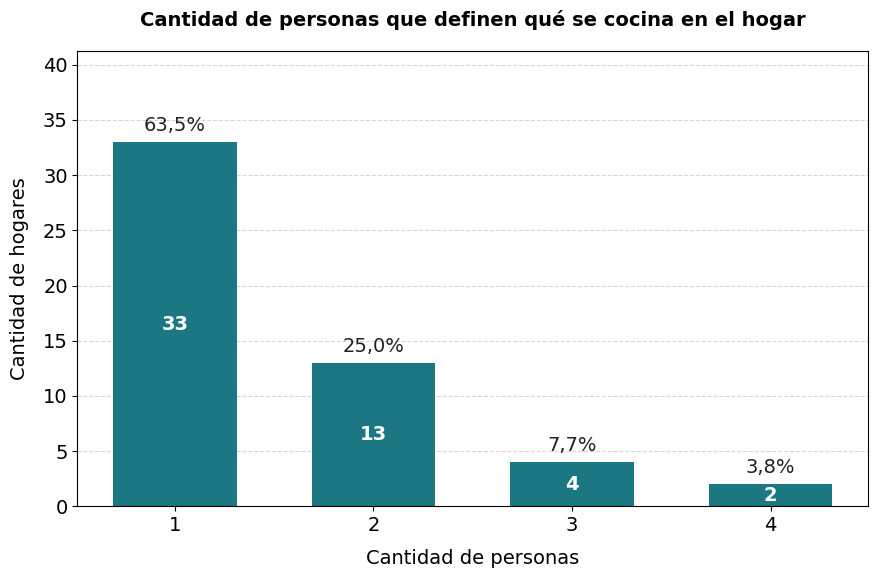

In [4]:
# Gráfico de barras VERTICAL: Cantidad de personas que definen qué se cocina
graficar_barras_verticales(
    etiquetas=conteo_1_1_cant.index,
    valores=conteo_1_1_cant.values,
    titulo="Cantidad de personas que definen qué se cocina en el hogar",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de hogares"
)


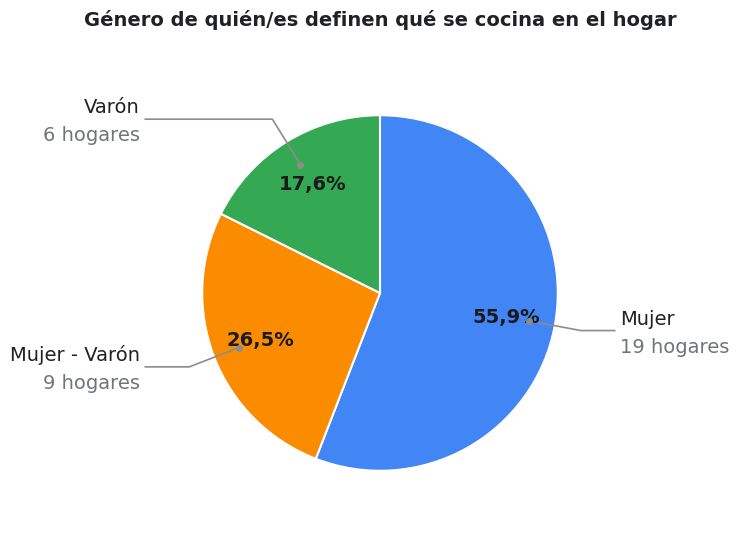

In [5]:
# Gráfico de torta: Género de quién/es definen qué se cocina (sin 'Se desconoce')
graficar_torta(
    categorias=conteo_1_1_gen.index,
    valores=conteo_1_1_gen.values,
    titulo="Género de quién/es definen qué se cocina en el hogar",
    unidad="hogares"
)


## 5. Pregunta 1.2: Quiénes se encargan de las compras


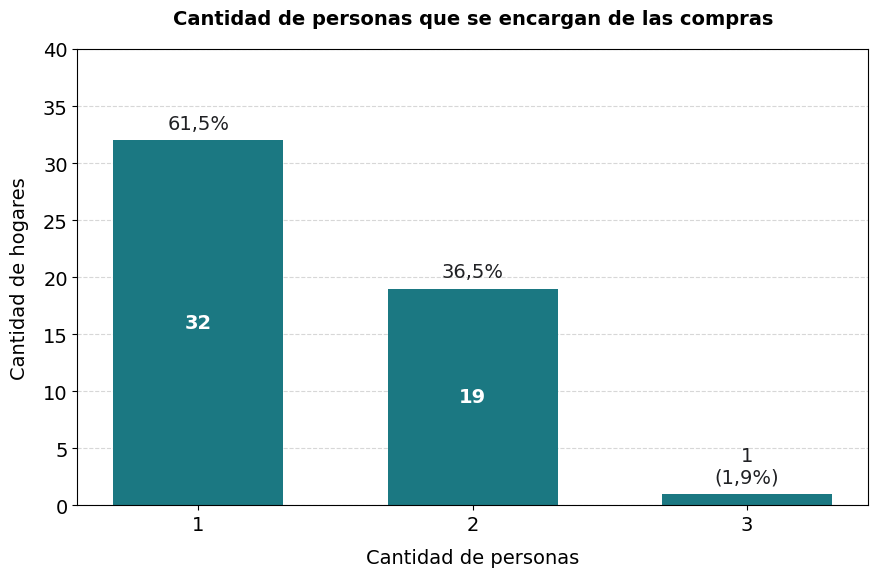

In [6]:
# Gráfico de barras VERTICAL: Cantidad de personas que se encargan de las compras
graficar_barras_verticales(
    etiquetas=conteo_1_2_cant.index,
    valores=conteo_1_2_cant.values,
    titulo="Cantidad de personas que se encargan de las compras",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de hogares"
)


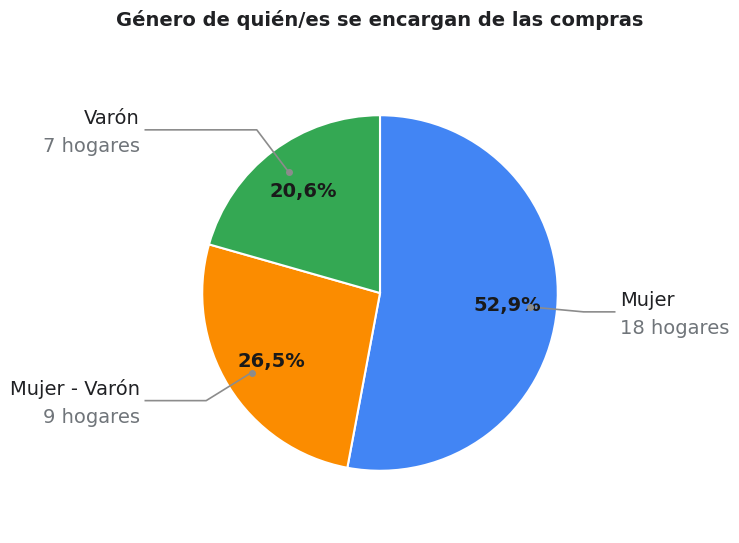

In [7]:
# Gráfico de torta: Género de quién/es se encargan de las compras (sin 'Se desconoce')
graficar_torta(
    categorias=conteo_1_2_gen.index,
    valores=conteo_1_2_gen.values,
    titulo="Género de quién/es se encargan de las compras",
    unidad="hogares"
)


## 6. Pregunta 1.3: Quiénes se encargan de preparar las comidas


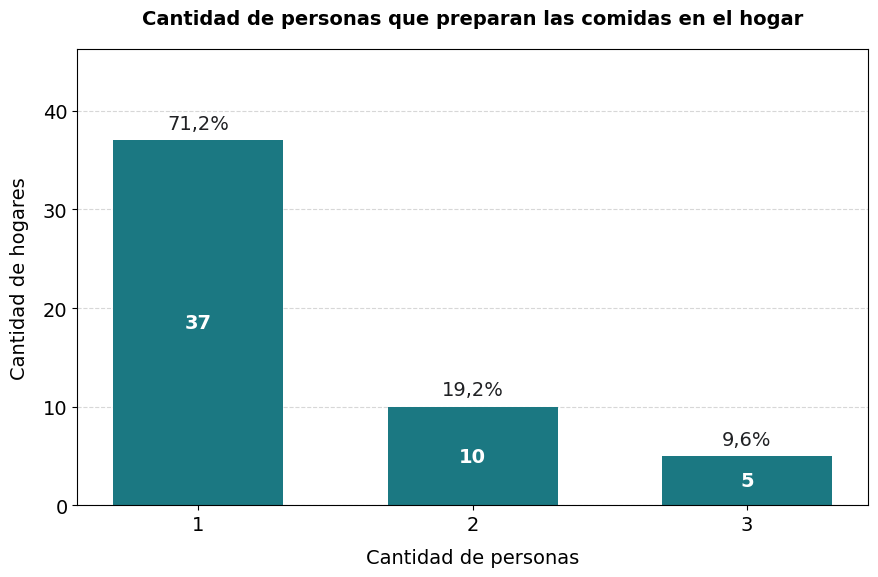

In [8]:
# Gráfico de barras VERTICAL: Cantidad de personas que preparan las comidas
graficar_barras_verticales(
    etiquetas=conteo_1_3_cant.index,
    valores=conteo_1_3_cant.values,
    titulo="Cantidad de personas que preparan las comidas en el hogar",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de hogares"
)


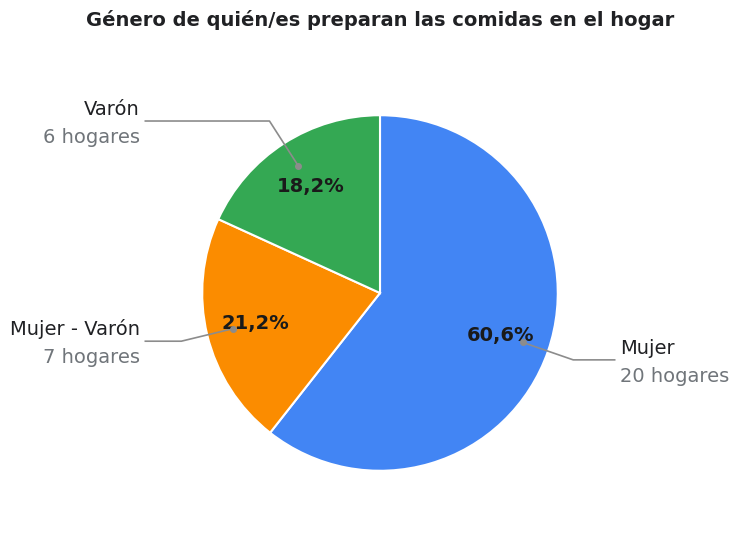

In [9]:
# Gráfico de torta: Género de quién se encarga de preparar las comidas (sin 'Se desconoce')
graficar_torta(
    categorias=conteo_1_3_gen.index,
    valores=conteo_1_3_gen.values,
    titulo="Género de quién/es preparan las comidas en el hogar",
    unidad="hogares"
)
